Theo mình hieeru là cái corner là dùng để có thể dùng các tính chất của engine value để có thể đánh gía dược các corner thông qua cong thức R = det(M) - k*trace(M) để có thể đánh giá đc điểm đó và lựa các threhold để có thể điểm ra đc các corner
- cái này có nhược điểm lớn là nếu thau đổi các tỉ lệ của các kích thước của window thì cái này sẽ ko tốt thep hướng nào đó thì mình cái này mình chưa rõ thì cái này minh cần cái `LoG`(Laplance of Guassian để thể biến các noise thành cá đường thằng đôngg nhất) kiểu cái này sẽ chia thanh nhiều tâng các dãy sau này sẽ kế thừa các dãy phía trc để có thể đánh giá cái hướng này mình ko hiểu lắm có cách nào đó thì cái đó kế thưa tại sao nó lại dùng cái tính nawgng kế thừa như nhân dần lên z có lí do j ko?

- cách này biểu diễn mỗi điểm ảnh sao đi đc guassian hóa thì mỗi điểm ảnh có thể hiểu theo rằng mỗi điểm đc hai giá trị lambda đc biểu dưới dạng eclipse sao khi đó đc hiểu là góc  và từ đó có thể biết đc giá trị của `R` thông qua caoong thức Harris
- sau đó có thể hiểu rằng mỗi điểm có thể hiểu là mỗi điểm có thể biểu diexn là cách khác nahu có thể đánh giá đc csc điểm đó có cách nào đó có thể biểu diễn rõ đc ko kiểu tại sao dựa vào các điểm đó tại sao có thể dựa vado đó có thể dánh giá đc là biểu đc cái dạng eclipse đó có ý nghĩa j cho mỗi cái engein đó ko cái đó mình chưa hiểu cái đó lắm có thể là nó xuất phhat cái tuef cái chính hình eclipse đó có thể hiểu theo sơ đồ cua thaaafu thì hiểu ràng các R đc biểu điễ nếU R lớn thì có thẻ hiểu là cái này biến thiên mạnh hay ko phụ phuộc cái trace duoaiws maxu tiến gần tới 0 thì có thể tieesn lên mnajngh owtr gốc đó

In [1]:
import numpy as np 
import matplotlib.pyplot as plt
AMBULADE_CONSTANT = np.array([0.299, 0.587, 0.114])
def convert2grey(img):
    return np.round(img[...,:3] @ AMBULADE_CONSTANT)

(2100, 2100)


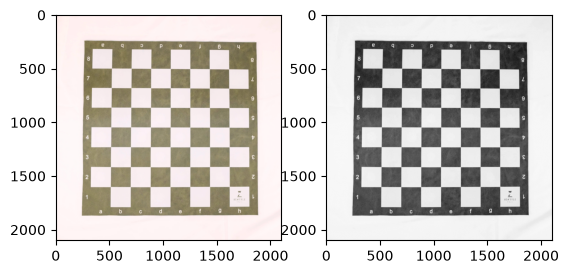

In [2]:
import cv2 as cv
img = cv.imread("chess.jpg")
grey = convert2grey(img)
print(f"{grey.shape}")
ax = plt.subplots(1, 2)[1]
ax[0].imshow(img, cmap="grey")
ax[1].imshow(grey, cmap="grey")
plt.show()

In [3]:
print(grey)

[[241. 241. 241. ... 239. 239. 239.]
 [241. 241. 241. ... 239. 239. 239.]
 [241. 241. 241. ... 239. 239. 239.]
 ...
 [247. 247. 247. ... 248. 248. 248.]
 [247. 247. 247. ... 248. 248. 248.]
 [247. 247. 247. ... 248. 248. 248.]]


In [4]:
sobelx = np.array(
    [[-1, 0, 1],
     [-2, 0, 2],
     [-1, 0, 1]]
)
sobely = np.array(
    [[-1, -2, -1],
     [0, 0, 0],
     [1, 2, 1]]
)

guassian_kernel = np.array([
    [1, 4, 6, 4, 1],
    [4, 16, 24, 16, 4],
    [6, 24, 36, 24, 6],
    [4, 16, 24, 16, 4],
    [1, 4, 6, 4, 1]
]) / 256

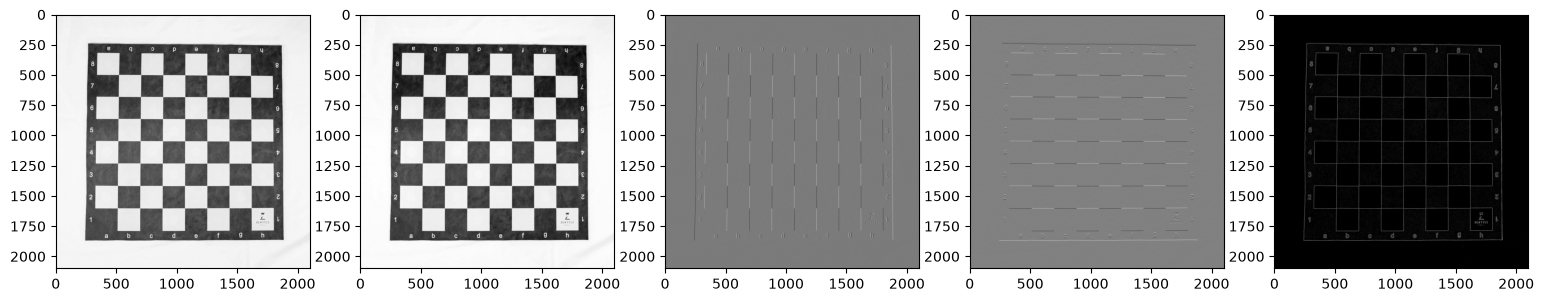

In [5]:
blur_grey = cv.filter2D(grey, -1, guassian_kernel)
Gx = cv.filter2D(grey, -1, sobelx)
Gy = cv.filter2D(grey, -1, sobely)
magtitude = np.sqrt(Gx**2 + Gy**2)
ax = plt.subplots(1, 5, figsize = (19, 10))[1]
ax[0].imshow(grey, cmap = "grey")
ax[1].imshow(blur_grey, cmap = "grey")
ax[2].imshow(Gx, cmap = "grey")
ax[3].imshow(Gy, cmap = "grey")
ax[4].imshow(magtitude, cmap = "grey")
plt.show()

``` python
def gaussian_blur(img, sigma):
"""Làm mờ Gauss. Được phép gọi scipy.ndimage.gaussian_filter."""
def structure_tensor(img, sigma_i, sigma_d):
"""Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
sigma_d: độ mờ trước khi lấy đạo hàm.
sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
-> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
"""
def harris_response(img, sigma_i, sigma_d, k=0.04):
"""Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
def nms_2d(response, window=3):
"""Cực đại địa phương trong cửa sổ window x window. -> mảng bool."""

# ---- Biến thể A1 ----------------------------------------------------
def scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10):
"""Danh sách sigma_n = xi^n * sigma0. -> mảng 1D."""
def log_normalized(img, sigma):
"""Laplacian chuẩn hoá theo tỉ lệ: sigma^2 * |Lxx + Lyy|."""
def harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0):
"""Harris-Laplace (Mikolajczyk & Schmid 2004).
Bước 1: mỗi sigma -> harris_response -> nms_2d -> ngưỡng.
Bước 2: giữ điểm chỉ khi |LoG| là cực đại địa phương theo trục tỉ lệ.
-> mảng (N, 4): (row, col, sigma, response).
"""

# ---- Đo đạc ---------------------------------------------------------
def repeatability(pts_a, pts_b, transform, img_shape, eps=3.0):
"""Tỉ lệ điểm của ảnh A tìm lại được trong ảnh B sau phép biến đổi.
transform: hàm (row, col) của A -> (row, col) tương ứng ở B.
Chỉ tính trên các điểm mà ảnh chiếu còn nằm trong B.
-> số thực trong [0, 1].
"""
```

In [6]:
def guassian_blur(img, sigma):
    from scipy.ndimage import gaussian_filter
    filtered_image = gaussian_filter(img, sigma = sigma)
    # filtered_image = cv.filter2D(img, -1, guassian_kernel)

    return filtered_image

In [7]:
print(guassian_blur(grey, 1.4))

[[241.         241.         240.99994664 ... 239.1367231  239.03403939
  239.00583706]
 [241.         241.         240.9999531  ... 239.1367231  239.03403939
  239.00583706]
 [241.00002927 241.00002927 240.99999371 ... 239.13674837 239.03406766
  239.00586616]
 ...
 [247.         247.         247.         ... 247.8819701  247.97061458
  247.994961  ]
 [247.         247.         247.         ... 247.86793087 247.96711929
  247.99436163]
 [247.         247.         247.         ... 247.86407496 247.9661593
  247.99419701]]


- Tiếp theo làm cái tensor có hai loại sigma
    - $\sigma_D$: Differenatation Scale - độ mờ trc khi xử lí ảnh
    - $\sigma_I$: Integration Scale - Bán kính vùng cấu trúc

In [8]:
k = 0.05 # Chose k is already chosen in document at the requirement section
def structure_tensor(img, sigma_i, sigma_d):
    """Ma trận mô-men bậc hai theo công thức (1), đã nhân sigma_d**2.
    sigma_d: độ mờ trước khi lấy đạo hàm.
    sigma_i: bán kính cửa sổ lấy trung bình các tích đạo hàm.
    -> (Mxx, Mxy, Myy), mỗi phần tử cùng kích thước ảnh.
    """

    sobelx = np.array(
    [[-1, 0, 1],
     [-2, 0, 2],
     [-1, 0, 1]]
    )
    
    sobely = np.array(
        [[-1, -2, -1],
         [0, 0, 0],
         [1, 2, 1]]
    )

    filtered_image = guassian_blur(img, sigma= sigma_d)
    
    L_x = cv.filter2D(filtered_image, -1, sobelx)
    L_y = cv.filter2D(filtered_image, -1, sobely)
    L_xL_y = L_x * L_y

    # print(L_x)

    Mxx = guassian_blur(L_x * L_x, sigma_i)
    Myy = guassian_blur(L_y * L_y, sigma_i)
    Mxy = guassian_blur(L_xL_y, sigma_i)

    return Mxx, Mxy, Myy

In [9]:
def harris_response(img, sigma_i, sigma_d, k=0.04):
    """Đáp ứng R theo công thức (2). -> mảng float cùng kích thước ảnh."""
    Mxx, Mxy, Myy = structure_tensor(img, sigma_i, sigma_d)
    # print(Mxx, Mxy, Myy)
    # print(Mxx)

    det = (Mxx * Myy) - Mxy ** 2
    trace = Mxx + Myy
    # Không hiểu sao ra cái công thức này cần tìm hieru
    R = det - k * (trace * trace)
    # print(R)
    return R

In [10]:
def maxSliding2d(reponse, W):
    from collections import deque
    def maxSliding1D(arr, W):
        dq = deque()
        res = []
        for i, val in enumerate(arr):
            if dq and dq[0] < i  - W + 1:
                dq.popleft()
            while dq and arr[dq[-1]] <= val:
                dq.pop()
            dq.append(i)
            if i >= W - 1:
                res.append(arr[dq[0]])
        return res
        
    N = len(response)
    M = len(response[0])
    print(f"M x N ({M}, {N})")

    row_max = []
    for r in range(N):
        row_max.append(maxSliding1D(response[r], W))
    col_max_matrix = []
    transponsed_matrix = list((zip(*row_max)))

    for col in transponsed_matrix:
        col_max_matrix.append(maxSliding1D(list(col), W))
    result = list(zip(*col_max_matrix))

    return result

response = [[0, 7, 6, 4, 4, 8, 0, 6],
           [2, 0, 5, 9, 7, 7, 7, 7],
           [5, 1, 8, 4, 5, 3, 1, 9],
           [7, 6, 4, 8, 5, 4, 4, 2],
           [0, 5, 8, 0, 8, 8, 2, 6],
           [1, 7, 7, 3, 0, 9, 4, 8],
           [6, 7, 7, 1, 3, 4, 4, 0],
           [5, 1, 7, 6, 9, 7, 3, 9]]
maxSliding2d(response, 3)

M x N (8, 8)


[(8, 9, 9, 9, 8, 9),
 (8, 9, 9, 9, 7, 9),
 (8, 8, 8, 8, 8, 9),
 (8, 8, 8, 9, 9, 9),
 (8, 8, 8, 9, 9, 9),
 (7, 7, 9, 9, 9, 9)]

In [11]:
def nms_2d(response, window=3):
    """Cực đại địa phương trong cửa sổ window x window. -> mảng bool."""
    H, W = response.shape
    r = window // 2
    out = np.zeros((H, W), dtype=bool)
    for i in range(H):
        for j in range(W):
            patch = response[max(0, i-r):i+r+1, max(0, j-r):j+r+1]
            out[i, j] = response[i, j] == patch.max()
    return out

In [12]:
def harris_classic(img, sigma_i=2.0, sigma_d=1.4, k=0.04, thresh_rel=0.01):
    """Harris một tỉ lệ: R -> nms_2d -> ngưỡng tương đối theo max(R).
    -> mảng (N, 3): (row, col, response), sắp xếp giảm dần theo response.
    """

    R = harris_response(img, sigma_i= sigma_i, sigma_d = sigma_d, k = k)
    nms = nms_2d(R)
    nms = nms & (R > thresh_rel * R.max())
    return nms

In [13]:
def scale_pyramid(sigma0=1.2, xi=1.2, n_levels=10):
    """Danh sách sigma_n = xi^n * sigma0. -> mảng 1D."""
    pyramid = np.zeros(n_levels + 1)
    for i in range(n_levels + 1):
        pyramid[i] = sigma0 * xi ** i
    return pyramid

- Theo tỉ lệ là kiểu như ghép chồng nhiều điểm lên có các tỉ lệ khác nhau r từ đó có thể ghép nhiefu layer lại với nhau r giữ lại các điểm ảnh có điểm nổi bật nhất
- í tưởng đơn giản là sẽ trông nhiều ảnh trên nhiều tỉ lệ lên với nhau r từ đó rút ra được hàng xóm giá trị lớ nhất

- cái này có ván đề là threhold của LoG thì mình sẽ sau khi xử lí trục xong thì mình mới quyết định giữ lại hay ko
- với cái classic dùng sai mục đích lẽ ra mình nên dùng cái cái này ở trên thì có vẽ đúng hơn thì cái này mình cần sửa lại tí
- Thì ddaafu tiên bắt tay vào làm liền

In [14]:
def log_normalized(img, sigma):
    """Laplacian chuẩn hoá theo tỉ lệ: sigma^2 * |Lxx + Lyy|."""
    filtered_image = guassian_blur(img, sigma= sigma)
    sobel_xx = np.array([
        [1, 0, -2, 0, 1],
        [4, 0, -8, 0, 4],
        [6, 0, -12, 0, 6],
        [4, 0, -8, 0, 4],
        [1, 0, -2, 0, 1],
    ])
    sobel_yy = sobel_xx.T
    L_xx = cv.filter2D(filtered_image, -1, sobel_xx)
    L_yy = cv.filter2D(filtered_image, -1, sobel_yy)

    norm = (sigma ** 2) * np.abs(L_xx * L_xx + L_yy + L_yy)

    return norm
    
def harris_laplace(img, sigmas, k=0.04, thresh_rel=0.01, log_thresh=0.0):
    """Harris-Laplace (Mikolajczyk & Schmid 2004).
    Bước 1: mỗi sigma -> harris_response -> nms_2d -> ngưỡng.
    Bước 2: giữ điểm chỉ khi |LoG| là cực đại địa phương theo trục tỉ lệ.
    -> mảng (N, 4): (row, col, sigma, response).
    """

    classic_log_save = []
    
    for sigma in sigmas:
        sigma_i = sigma
        sigma_d = 0.7 * sigma
        
        classic = harris_classic(img, sigma_d = sigma_d, sigma_i = sigma_i)
        log = log_normalized(img, sigma_d)
        classic_log_save.append((classic, log))
        
    actual_result = []

    # Explore entire picture of pixel 
    # That can find maximum of LoG in each position
    # Like when you stack the layers in each image with different sigma in LoG
    for x in range(img.shape[0]):
        for y in range(img.shape[1]):
            maximum = classic_log_save[0][1][x, y] # Take LoG at initial Scale
            optimal_sigma = sigmas[0]
            is_corner = False
            for i in range(1, len(sigmas)):
                if classic_log_save[i][0][x, y]:
                    is_corner = True
                if maximum <  classic_log_save[i][1][x, y]:
                    maximum = classic_log_save[i][1][x, y]
            if maximum > log_thresh and is_corner:
                actual_result.append((x, y, sigmas[i], classic_log_save[i][0][x, y]))

    return actual_result

Image Size: (2100, 2100)


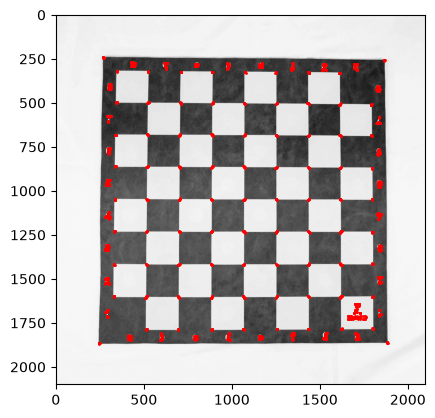

In [15]:
sigmas = scale_pyramid()
pos = np.array(harris_laplace(grey, sigmas))
print(f"Image Size: {grey.shape}")
plt.imshow(grey, cmap = 'grey')
# print(pos[: , 0])
# print(pos[1, 0], pos[1 , 1])
plt.scatter(pos[:, 1].astype(np.int64), pos[: , 0].astype(np.int64), s=1, c="red")
plt.show()

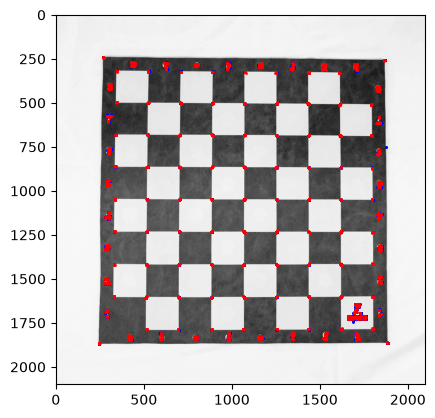

In [17]:
dst = cv.cornerHarris(grey.astype(np.float32), blockSize=2, ksize=3, k=0.04)
corner_only_img = np.zeros_like(img)


ys, xs = np.nonzero(dst > 0.01 * dst.max())
plt.imshow(grey, cmap = 'grey')
plt.scatter(xs, ys, s=1, c="blue")
plt.scatter(pos[:, 1].astype(np.int64), pos[: , 0].astype(np.int64), s=1, c="red")
plt.show()